[Text(0, 0.5, 'Firearm seizures per 1000 residents')]

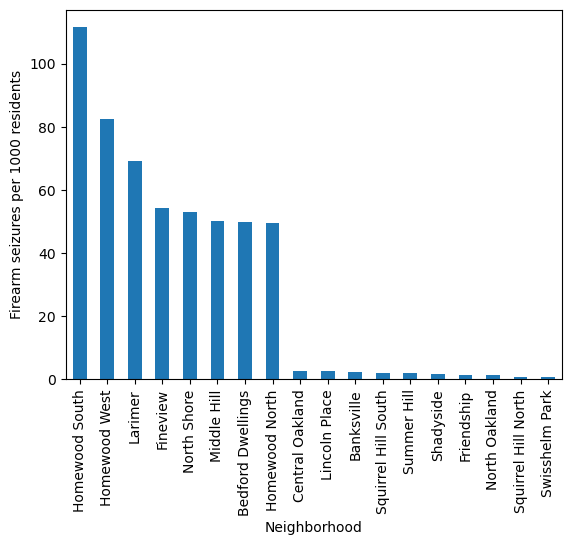

In [59]:
import pandas as pd

firearm_data = pd.read_csv("https://data.wprdc.org/datastore/dump/e967381d-d7e9-48e3-a2a2-39262f7fa5c4")
firearm_data = firearm_data[firearm_data["neighborhood"].notna()]
firearm_data = firearm_data["neighborhood"].value_counts()

population_data = pd.read_csv("https://data.wprdc.org/datastore/dump/a8414ed5-c50f-417e-bb67-82b734660da6")
population_data = population_data.set_index('Neighborhood')
population_data = population_data["2020_Total_Population"]

firearm_data_per_capita = firearm_data.div(population_data)
firearm_data_per_capita *= 1000
firearm_data_per_capita = pd.concat([firearm_data_per_capita.nlargest(10), firearm_data_per_capita.nsmallest(10)]).sort_values(ascending=False)
firearm_data_per_capita = firearm_data_per_capita[firearm_data_per_capita < 300]

plot = firearm_data_per_capita.plot.bar()
plot.set(xlabel="Neighborhood")
plot.set(ylabel="Firearm seizures per 1000 residents")